# code_189 · Match a score to the inspection decision

**Book:** section 36.2. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_36_GUIDE.md), [execution evidence](../CHAPTER_36_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_189).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evaluation contracts identify the population, sampling unit, available information, score direction and decision consequences. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7789;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 7789


<a id="classification-and-query-denominators"></a>
 ## Hold whole inspection days apart and freeze the decision threshold
 Generate 120 independent days with 12 candidate sites per day: 70 source, 20 development and 30 final. Site features contain severity, load and normalized coordinate. Outcomes are binary actionable findings with nonlinear severity and day-level prevalence variation. A source-fitted logistic classifier receives the visible features; a threshold minimizes development cost FN=5, FP=1 on a fixed grid, then remains locked. Report the final confusion matrix, ROC AUC, average precision (the step-weighted PR summary, not a trapezoidal integral), log loss and Brier score. Capacity-three decisions rank within each day, with macro precision, recall on days that have positives, and NDCG using binary gains; empty-positive days contribute zero NDCG and are counted separately. These denominator conventions are explicit, not universal defaults.


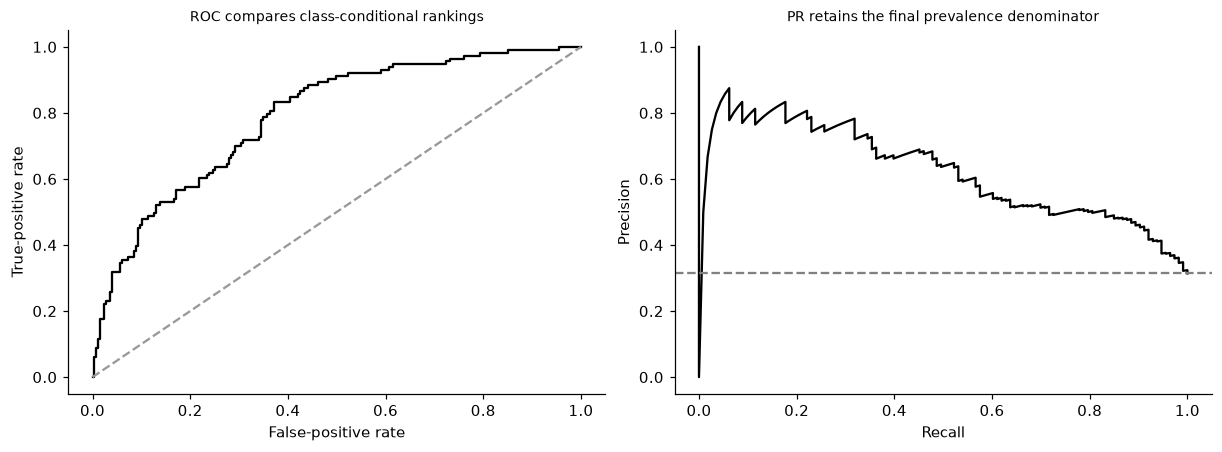

In [2]:
from sklearn.linear_model import LogisticRegression,Ridge
from sklearn.metrics import confusion_matrix,roc_auc_score,average_precision_score,log_loss,brier_score_loss,precision_recall_curve,roc_curve
days=120;sites=12;day=np.repeat(np.arange(days),sites);coord=np.tile(np.linspace(0,1,sites),days);load=np.repeat(rng.uniform(.5,1.5,days),sites);severity=rng.normal(size=days*sites);context=np.repeat(rng.normal(scale=.7,size=days),sites);X=np.c_[severity,load,coord];prob=expit(-2+1.6*severity+.6*load+context);Y=rng.binomial(1,prob);source=day<70;dev=(day>=70)&(day<90);final=day>=90;clf=LogisticRegression(C=1,max_iter=300).fit(X[source],Y[source]);pdv=clf.predict_proba(X[dev])[:,1];grid=np.linspace(.05,.8,76);costs=[np.mean(5*((pdv<t)&(Y[dev]==1))+((pdv>=t)&(Y[dev]==0))) for t in grid];threshold=float(grid[np.argmin(costs)]);pf=clf.predict_proba(X[final])[:,1];yf=Y[final];cm=confusion_matrix(yf,pf>=threshold,labels=[0,1]);qq=pf.reshape(30,12);rel=yf.reshape(30,12);order=np.argsort(-qq,axis=1,kind='stable');prec=[];rec=[];ndcg=[]
for k in range(1,6):
    picked=np.take_along_axis(rel,order[:,:k],axis=1);gain=1/np.log2(np.arange(2,k+2));ideal=np.sort(rel,axis=1)[:,::-1][:,:k]@gain;dcg=picked@gain;positive=rel.sum(1)>0;prec.append(float(picked.mean()));rec.append(float(np.mean(picked.sum(1)[positive]/rel.sum(1)[positive])));ndcg.append(float(np.mean(np.divide(dcg,ideal,out=np.zeros_like(dcg),where=ideal>0))))
assert cm.sum()==360 and source.sum()==840;assert set(day[source]).isdisjoint(set(day[final]));assert np.isclose(prec[2],np.take_along_axis(rel,order[:,:3],axis=1).sum()/90)
RESULTS.update(day_roles=[70,20,30],threshold=threshold,confusion=cm.tolist(),prevalence=float(yf.mean()),ROC_AUC=float(roc_auc_score(yf,pf)),average_precision=float(average_precision_score(yf,pf)),log_loss=float(log_loss(yf,pf)),Brier=float(brier_score_loss(yf,pf)),capacities=list(range(1,6)),query_macro_precision=prec,positive_query_macro_recall=rec,query_macro_NDCG=ndcg,empty_positive_days=int((rel.sum(1)==0).sum()),final_cost=float(np.mean(5*((pf<threshold)&(yf==1))+((pf>=threshold)&(yf==0)))))
fpr,tpr,_=roc_curve(yf,pf);pcurve,rcurve,_=precision_recall_curve(yf,pf);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(fpr,tpr,color='black');axes[0].plot([0,1],[0,1],'--',color='.6');axes[0].set(xlabel='False-positive rate',ylabel='True-positive rate',title='ROC compares class-conditional rankings');axes[1].plot(rcurve,pcurve,color='black');axes[1].axhline(yf.mean(),linestyle='--',color='.5');axes[1].set(xlabel='Recall',ylabel='Precision',title='PR retains the final prevalence denominator');plt.show()


<a id="metric-matched-to-use"></a>
 ## Inspect classification, capacity and structural validity together
 For the same sites, generate a deflection field load×x×(1−x), with exactly zero support displacement at the two endpoint sites. A separate source-fitted ridge model uses load, coordinate and squared coordinate without the load-coordinate interaction; it is a deliberately imperfect surrogate. Assess its signed residual map on the first predeclared final day and support displacement on all final days. Physical units are millimetres. The three-panel Visual A places its actual confusion matrix, within-day precision versus capacity and residual map beside their different questions. A good probability ordering cannot certify a displacement boundary.

 A separate exposure diagnostic retains complete generated relevance but simulates response with position examination probabilities from 1 down to 0.05. Compare raw responses with actual underlying findings by ranked position. These simulated missing responses are not negative relevance labels and do not fit or select any earlier model. Known complete judgments are stronger information than ordinary recommendation logs; this diagnostic does not claim to recover unknown relevance from deterministic exposure.


,rank,actual_finding_rate,observed_response_rate,examination_probability
0,1,0.800000,0.800000,1.000000
1,2,0.533333,0.500000,0.913636
2,3,0.433333,0.400000,0.827273
3,4,0.466667,0.366667,0.740909
4,5,0.400000,0.200000,0.654545
5,6,0.233333,0.133333,0.568182
6,7,0.333333,0.166667,0.481818
7,8,0.133333,0.033333,0.395455
8,9,0.233333,0.133333,0.309091
9,10,0.100000,0.000000,0.222727


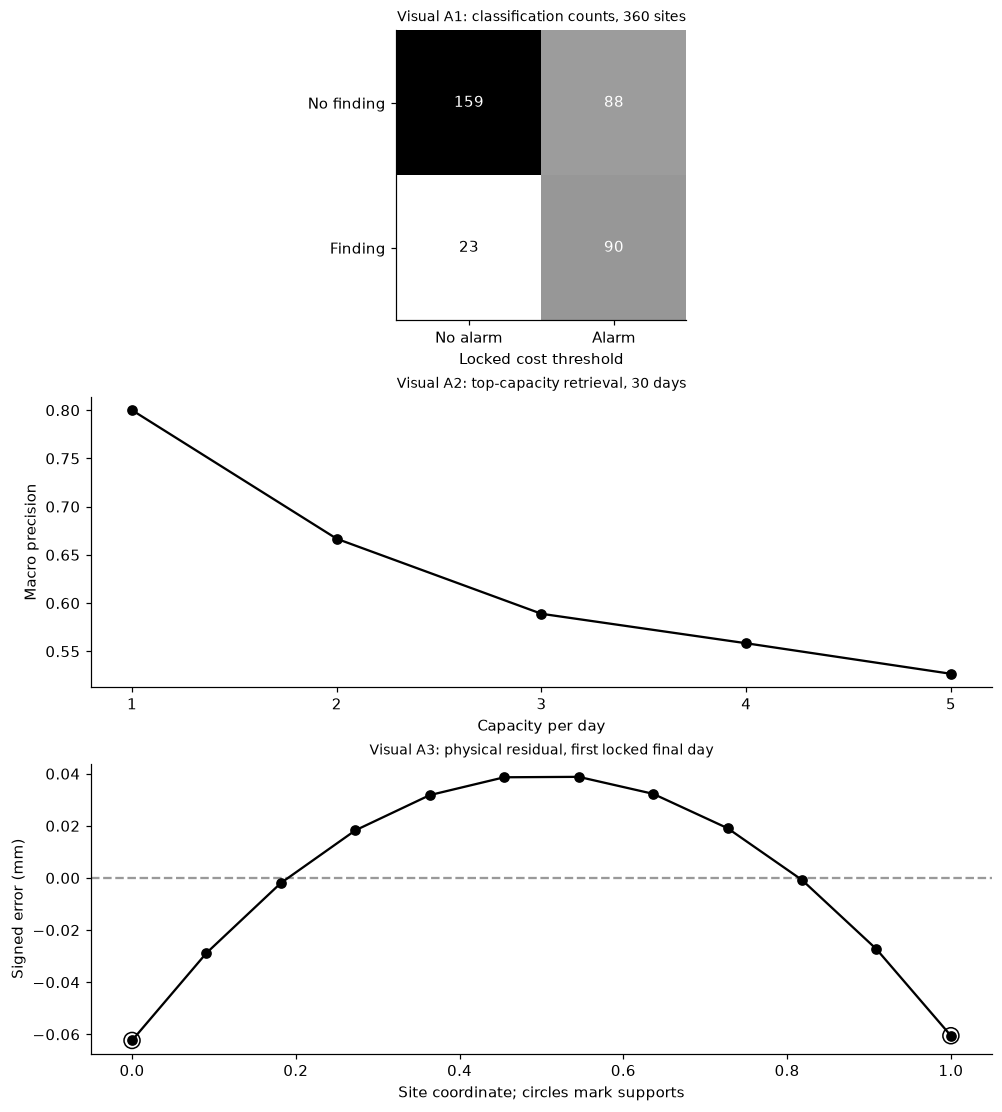

In [3]:
physical=np.c_[load,coord,coord**2];u=load*coord*(1-coord);surrogate=Ridge(alpha=.1).fit(physical[source],u[source]+rng.normal(scale=.01,size=source.sum()));uh=surrogate.predict(physical[final]).reshape(30,12);uf=u[final].reshape(30,12);err=uh-uf;boundary=float(np.max(abs(uh[:,[0,-1]])));assert np.allclose(uf[:,[0,-1]],0);assert err.shape==(30,12);examination=np.linspace(1,.05,12);ranked=np.take_along_axis(rel,order,axis=1);responses=ranked*rng.binomial(1,examination,size=ranked.shape);assert np.all(responses<=ranked)
RESULTS.update(physical_RMSE_mm=float(np.sqrt(np.mean(err**2))),maximum_support_displacement_mm=boundary,first_final_day=90,position_relevance=ranked.mean(0).tolist(),position_observed_response=responses.mean(0).tolist(),position_examination_probability=examination.tolist())
display(pd.DataFrame({'rank':np.arange(1,13),'actual_finding_rate':ranked.mean(0),'observed_response_rate':responses.mean(0),'examination_probability':examination}));fig,axes=plt.subplots(3,1,figsize=(9,10));axes[0].imshow(cm,cmap='Greys');
for i in range(2):
    for j in range(2):axes[0].text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
axes[0].set(xticks=[0,1],yticks=[0,1],xticklabels=['No alarm','Alarm'],yticklabels=['No finding','Finding'],xlabel='Locked cost threshold',title='Visual A1: classification counts, 360 sites');axes[1].plot(range(1,6),prec,'o-',color='black');axes[1].set(xticks=range(1,6),xlabel='Capacity per day',ylabel='Macro precision',title='Visual A2: top-capacity retrieval, 30 days');axes[2].axhline(0,color='.6',linestyle='--');axes[2].plot(np.linspace(0,1,12),err[0],'o-',color='black');axes[2].scatter([0,1],err[0,[0,-1]],facecolors='none',edgecolors='black',s=110);axes[2].set(xlabel='Site coordinate; circles mark supports',ylabel='Signed error (mm)',title='Visual A3: physical residual, first locked final day');plt.show()


In [4]:
summary={'example_id':'code_189','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['source-fitted classifier and development-only cost threshold', 'ROC precision recall Brier log loss and query-macro top capacity metrics', 'observed exposure distinguished from complete generated relevance', 'one workflow confusion ranking and physical residual Visual A'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["source-fitted classifier and development-only cost threshold", "ROC precision recall Brier log loss and query-macro top capacity metrics", "observed exposure distinguished from complete generated relevance", "one workflow confusion ranking and physical residual Visual A"], "elapsed_seconds": 0.331, "example_id": "code_189", "hardware": "Darwin arm64 CPU", "results": {"Brier": 0.16936396054326572, "ROC_AUC": 0.7891154025294688, "average_precision": 0.6247403454408066, "capacities": [1, 2, 3, 4, 5], "confusion": [[159, 88], [23, 90]], "day_roles": [70, 20, 30], "empty_positive_days": 1, "final_cost": 0.5638888888888889, "first_final_day": 90, "log_loss": 0.5129578584548915, "maximum_support_displacement_mm": 0.07345644790804845, "physical_RMSE_mm": 0.025904649753885543, "position_examination_probability": [1.0, 0.9136363636363636, 0.8272727272727273, 0.740909090909091, 0.6545454545454545, 0.5681818181818181, 0.4818181818181818, 0.3954545